In [1]:
import pandas as pd 

In [2]:
df = pd.read_csv('ml_ready_data_tree_class_pcube_deramped.csv')
df.shape

(811833, 41)

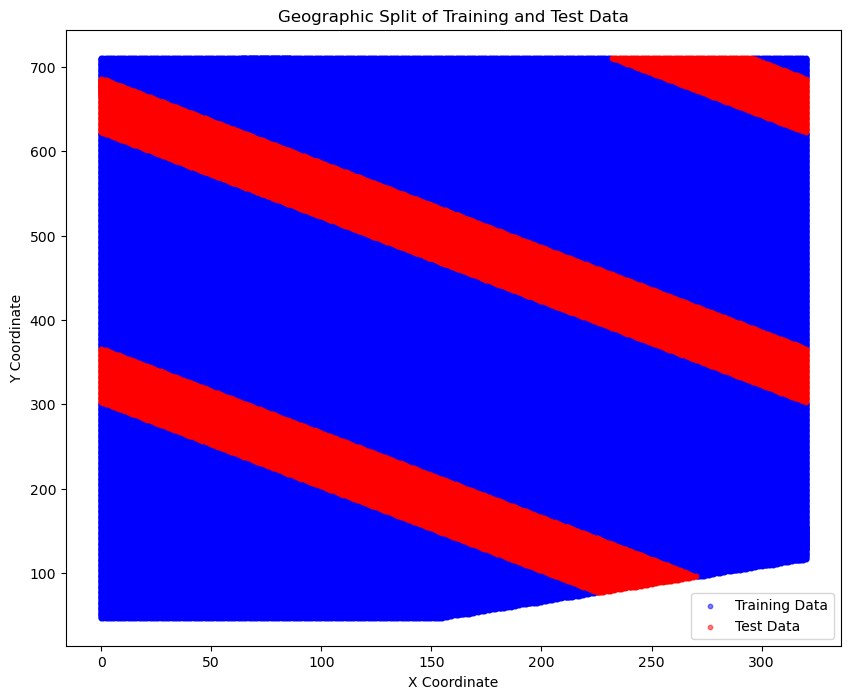

Training data size: 653955
Test data size: 157878
Actual test size ratio: 0.19447103037201


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def create_diagonal_swathes(data, x_col, y_col, swath_thickness):
    """
    Create swath labels for the data based on diagonal swathes.
    
    Parameters:
    - data: DataFrame with geographic coordinates.
    - x_col: Column name for x coordinates.
    - y_col: Column name for y coordinates.
    - swath_thickness: Thickness of each swath as a proportion of the x range.
    
    Returns:
    - DataFrame with an additional column 'swath' indicating the swath of each point.
    """
    x_min, x_max = data[x_col].min(), data[x_col].max()
    y_min, y_max = data[y_col].min(), data[y_col].max()
    x_range = x_max - x_min
    
    # Calculate the swath boundaries
    num_swathes = int(np.ceil(1 / swath_thickness))
    data['swath'] = ((data[x_col] + data[y_col] - x_min - y_min) / (x_range * swath_thickness)).astype(int) % num_swathes
    
    return data

def split_by_swath(data, swath_col, test_size=0.2, max_iterations=100):
    """
    Split the data into train and test sets based on swathes, aiming for the specified test_size.
    
    Parameters:
    - data: DataFrame with geographic coordinates.
    - swath_col: Column name indicating the swath of each point.
    - test_size: Proportion of the dataset to include in the test split.
    - max_iterations: Maximum number of iterations to attempt to achieve the desired split.
    
    Returns:
    - train_data: Training set.
    - test_data: Test set.
    """
    unique_swathes = data[swath_col].unique()
    n_swathes = len(unique_swathes)
    
    best_split = None
    best_diff = float('inf')
    
    for _ in range(max_iterations):
        n_test_swathes = max(1, int(n_swathes * test_size))
        test_swathes = np.random.choice(unique_swathes, size=n_test_swathes, replace=False)
        
        test_data = data[data[swath_col].isin(test_swathes)]
        train_data = data[~data[swath_col].isin(test_swathes)]
        
        actual_test_size = len(test_data) / len(data)
        diff = abs(actual_test_size - test_size)
        
        if diff < best_diff:
            best_diff = diff
            best_split = (train_data, test_data)
        
        if diff < 0.01:  # If within 1% of desired test_size, break
            break
    
    return best_split

def visualize_splits(train_data, test_data, x_col='x', y_col='y'):
    """
    Visualize the training and test splits based on x and y coordinates.
    
    Parameters:
    - train_data: DataFrame for the training data.
    - test_data: DataFrame for the test data.
    - x_col: Column name for x coordinates.
    - y_col: Column name for y coordinates.
    """
    plt.figure(figsize=(10, 8))
    plt.scatter(train_data[x_col], train_data[y_col], c='blue', label='Training Data', alpha=0.5, s=10)
    plt.scatter(test_data[x_col], test_data[y_col], c='red', label='Test Data', alpha=0.5, s=10)
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.title('Geographic Split of Training and Test Data')
    plt.show()

# Assume df is your DataFrame with 'x' and 'y' columns

# Define the column to use for swathes
x_column = 'x'
y_column = 'y'
swath_thickness = 0.2  # 15% of the x range

# Create diagonal swathes
df = create_diagonal_swathes(df, x_column, y_column, swath_thickness)

test_size=0.2
# Split the data based on the created swath column
train_data, test_data = split_by_swath(df, 'swath', test_size=test_size)

# Visualize the splits
visualize_splits(train_data, test_data, x_col=x_column, y_col=y_column)

# Verify the splits
print("Training data size:", len(train_data))
print("Test data size:", len(test_data))
print("Actual test size ratio:", len(test_data) / len(df))

In [16]:
test_data.to_csv(f'mldata__test_data__swath_{swath_thickness}__testsize_{test_size}.csv')
train_data.to_csv(f'mldata__train_data__swath_{swath_thickness}__testsize_{test_size}.csv')

In [12]:
print('Percetnate of test: ' , test_data.shape[0] / train_data.shape[0])

Percetnate of test:  0.17067040435371325
